# Module 9: Computer Vision: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-09-computer-vision/Module_9_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. ▶️ [Module 9 videos](https://www.youtube.com/playlist?list=PLI87agNzVTHQ) · 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/41e6f1ed006e818dbad4cc2fcbc0775e) · 💻 [Module 9 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-09-computer-vision)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## computer_vision_lesson.py

Module 9: Computer Vision: Practical Lesson
From pixels to perception with OpenCV, NumPy and a small neural network

Every image below ships with scikit-image, so there is nothing to download
(except the optional YOLO part at the end).

  Part 1  Images are arrays: shape, dtype, pixel values, grayscale, and the
          BGR vs RGB trap that turns red things blue.
  Part 2  Image processing: resizing with interpolation, a box blur and a
          sharpening kernel with cv2.filter2D, and Canny edge detection.
  Part 3  Face DETECTION with a classical cascade: where is the face?
          (Detection finds faces; recognition, which says WHOSE face, is a
          separate later step.)
  Part 4  A neural network that reads digits (64 -> 16 -> 16 -> 10, the
          small cousin of the 784-16-16-10 network from class), and a test
          of how badly it copes when the digits are shifted by 2 pixels.
  Part 5  (Optional) Real-time-style object detection with a pre-trained
          YOLOv8 model. Runs only if `ultralytics` is installed:
          pip install ultralytics   (in Colab: !pip install ultralytics)

Run:  python computer_vision_lesson.py
Needs: opencv-python, numpy, matplotlib, scikit-image, scikit-learn

In [1]:
import os
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")  # save figures to files; no window needed
import matplotlib.pyplot as plt
from skimage import data
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
SEED = 42

### `header()`

In [2]:
def header(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

### `part1_images_are_arrays()`

In [3]:
# =============================================================================
# PART 1: IMAGES ARE ARRAYS
# =============================================================================
def part1_images_are_arrays():
    header("PART 1: AN IMAGE IS JUST A GRID OF NUMBERS")
    rgb = data.astronaut()                       # scikit-image gives RGB order
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)   # what cv2.imread() would give you
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    h, w, c = bgr.shape
    print(f"Colour image shape: {bgr.shape}  ->  {h} rows (height) x {w} columns (width) x {c} channels")
    print(f"Data type: {bgr.dtype}  ->  every value is a whole number from {bgr.min()} to {bgr.max()}")
    print(f"Total numbers in this one photo: {bgr.size:,}")
    print(f"Grayscale shape: {gray.shape}  ->  one channel, {gray.size:,} numbers (a 66% saving)")

    y, x = 250, 250
    b_val, g_val, r_val = bgr[y, x]
    print(f"\nPixel at (y={y}, x={x}) in OpenCV's BGR order: B={b_val}, G={g_val}, R={r_val}")
    print(f"Same pixel in RGB order:                     R={rgb[y, x, 0]}, G={rgb[y, x, 1]}, B={rgb[y, x, 2]}")
    print(f"Same pixel in grayscale: {gray[y, x]} (0 = black, 255 = white)")

    # The BGR trap: what happens if you show OpenCV's BGR array with Matplotlib (which expects RGB)
    patch = rgb[350:450, 120:220].reshape(-1, 3).mean(axis=0).round()
    r, g, b = (int(v) for v in patch)
    print(f"\nAverage colour of a patch (rows 350-450, columns 120-220):")
    print(f"  read correctly as RGB:     R={r}, G={g}, B={b}  -> reddish")
    print(f"  same numbers read as BGR:  R={b}, G={g}, B={r}  -> bluish")
    print("That is the BGR trap: show OpenCV's BGR array with Matplotlib (which expects RGB)")
    print("and red turns blue. Always call cv2.cvtColor(img, cv2.COLOR_BGR2RGB) before plt.imshow().")

    norm = gray / 255.0
    print(f"\nFor neural networks we scale to 0..1: min {norm.min():.2f}, max {norm.max():.2f}, mean {norm.mean():.3f}")
    return rgb, bgr, gray

### `part2_image_processing()`

In [4]:
# =============================================================================
# PART 2: IMAGE PROCESSING (image in -> modified image out)
# =============================================================================
def part2_image_processing(bgr, gray):
    header("PART 2: RESIZE, BLUR, SHARPEN AND FIND EDGES")
    half = cv2.resize(bgr, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    double = cv2.resize(bgr, (0, 0), fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    print(f"Downscale 50% with INTER_AREA:  {bgr.shape[:2]} -> {half.shape[:2]}")
    print(f"Upscale 200% with INTER_CUBIC:  {bgr.shape[:2]} -> {double.shape[:2]}")

    # Convolution: slide a small kernel over the image, replace each pixel by a weighted sum
    blur_kernel = np.ones((3, 3), np.float32) / 9.0                       # average of 9 neighbours
    sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
    blurred = cv2.filter2D(gray, -1, blur_kernel)
    sharpened = cv2.filter2D(gray, -1, sharpen_kernel)
    print("\nBlur kernel (each weight 1/9):\n", blur_kernel.round(3))
    print("Sharpen kernel (centre +5, neighbours -1):\n", sharpen_kernel.astype(int))

    def sharpness(img):   # variance of the Laplacian: higher = more fine detail
        return cv2.Laplacian(img, cv2.CV_64F).var()
    print(f"\nSharpness score (variance of Laplacian):")
    print(f"  original {sharpness(gray):8.1f}")
    print(f"  blurred  {sharpness(blurred):8.1f}   <- detail smoothed away")
    print(f"  sharpened{sharpness(sharpened):8.1f}   <- edges exaggerated")

    edges = cv2.Canny(gray, threshold1=50, threshold2=200)
    edges_loose = cv2.Canny(gray, threshold1=20, threshold2=60)
    pct = lambda e: (e > 0).mean() * 100
    print(f"\nCanny edges (thresholds 50/200): {pct(edges):.1f}% of pixels are edges")
    print(f"Canny edges (thresholds 20/60):  {pct(edges_loose):.1f}%   <- lower thresholds keep weaker edges")
    return blurred, sharpened, edges

### `detect_faces()`: Use OpenCV's Haar cascade if it is available, otherwise scikit-image's LBP cascade.

In [5]:
# =============================================================================
# PART 3: FACE DETECTION (image in -> boxes out)
# =============================================================================
def detect_faces(gray):
    """Use OpenCV's Haar cascade if it is available, otherwise scikit-image's LBP cascade."""
    haar = None
    if hasattr(cv2, "CascadeClassifier") and hasattr(cv2, "data"):
        path = os.path.join(cv2.data.haarcascades, "haarcascade_frontalface_default.xml")
        if os.path.exists(path):
            haar = cv2.CascadeClassifier(path)
    if haar is not None and not haar.empty():
        boxes = haar.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        return [tuple(int(v) for v in b) for b in boxes], "OpenCV Haar cascade (Viola-Jones)"

    from skimage.feature import Cascade   # same idea, LBP features instead of Haar features
    detector = Cascade(data.lbp_frontal_face_cascade_filename())
    found = detector.detect_multi_scale(img=gray, scale_factor=1.1, step_ratio=1,
                                        min_size=(60, 60), max_size=(300, 300))
    return [(d["c"], d["r"], d["width"], d["height"]) for d in found], "scikit-image LBP cascade"

### `part3_face_detection()`

In [6]:
def part3_face_detection(bgr, gray):
    header("PART 3: FACE DETECTION (WHERE is the face?)")
    boxes, method = detect_faces(gray)
    print(f"Detector: {method}")
    print(f"Faces found: {len(boxes)}")
    annotated = bgr.copy()
    for (x, y, w, h) in boxes:
        print(f"  box x={x}, y={y}, width={w}, height={h}")
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 0, 255), 3)        # red in BGR
        cv2.putText(annotated, "Face", (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
    print("Detection only says WHERE a face is. Recognition (WHOSE face) would crop this box")
    print("and compare a 128-number face embedding against a database of known people.")

    # Classical cascades struggle with rotated faces: try the same photo turned 90 degrees
    rotated = cv2.rotate(gray, cv2.ROTATE_90_CLOCKWISE)
    rot_boxes, _ = detect_faces(rotated)
    print(f"\nSame photo rotated 90 degrees: {len(rot_boxes)} face(s) found  <- cascades expect upright, frontal faces")
    return annotated

### `shift_images()`: Move every 8x8 digit dx pixels to the right (empty space fills with 0).

In [7]:
# =============================================================================
# PART 4: A NEURAL NETWORK THAT READS DIGITS
# =============================================================================
def shift_images(X, dx, size=8):
    """Move every 8x8 digit dx pixels to the right (empty space fills with 0)."""
    imgs = X.reshape(-1, size, size)
    shifted = np.zeros_like(imgs)
    shifted[:, :, dx:] = imgs[:, :, :size - dx]
    return shifted.reshape(len(X), -1)

### `part4_digit_network()`

In [8]:
def part4_digit_network():
    header("PART 4: A NEURAL NETWORK THAT READS HANDWRITTEN DIGITS")
    digits = load_digits()
    X, y = digits.data / 16.0, digits.target
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)

    net = MLPClassifier(hidden_layer_sizes=(16, 16), activation="relu", max_iter=2000, random_state=SEED)
    net.fit(X_train, y_train)

    n_params = sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)
    print("Architecture: 64 inputs (8x8 pixels) -> 16 -> 16 -> 10 outputs")
    print(f"Learnable weights and biases: {n_params:,}")
    print("(The class example, 784 -> 16 -> 16 -> 10 for 28x28 images, has 13,002.)")
    acc = net.score(X_test, y_test)
    print(f"\nTest accuracy on {len(X_test)} unseen digits: {acc:.1%}")

    print("\nNow shift every test digit sideways and ask the same network again:")
    for dx in (1, 2):
        shifted_acc = net.score(shift_images(X_test, dx), y_test)
        print(f"  shifted {dx} pixel(s) right: {shifted_acc:.1%}")
    print("A plain dense network learns 'which pixels light up', so a small shift confuses it.")
    print("Convolutional networks (CNNs) and YOLO slide filters across the image, which fixes this.")
    return net, X_test, y_test, digits

### `part5_yolo()`

In [9]:
# =============================================================================
# PART 5 (OPTIONAL): YOLO OBJECT DETECTION
# =============================================================================
def part5_yolo(rgb):
    header("PART 5 (OPTIONAL): OBJECT DETECTION WITH YOLOv8")
    try:
        from ultralytics import YOLO
    except ImportError:
        print("ultralytics is not installed, so this part is skipped.")
        print("To try it: pip install ultralytics   (in Colab: !pip install ultralytics)")
        return None
    model = YOLO("yolov8n.pt")           # small pre-trained model, 80 everyday object classes
    scene = data.coffee()                # a coffee cup on a table
    results = model(scene, verbose=False)[0]
    print(f"YOLOv8n looked at the image ONCE and found {len(results.boxes)} object(s):")
    for box in results.boxes:
        name = results.names[int(box.cls)]
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        print(f"  {name:<12} confidence {float(box.conf):.0%}  box ({x1:.0f}, {y1:.0f}) to ({x2:.0f}, {y2:.0f})")
    plotted = results.plot()             # returns the image with boxes drawn on it
    return plotted

### `plot_all()`

In [10]:
# =============================================================================
# PLOT
# =============================================================================
def plot_all(rgb, bgr, gray, blurred, sharpened, edges, annotated, net, X_test, y_test, yolo_img):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
    show = [
        (rgb, "A) Original (RGB)", None),
        (bgr, "B) BGR shown as if RGB: the trap", None),
        (gray, "C) Grayscale: one channel", "gray"),
        (blurred, "D) 3x3 box blur", "gray"),
        (sharpened, "E) Sharpening kernel", "gray"),
        (edges, "F) Canny edges (50 / 200)", "gray"),
        (cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB), "G) Face detection", None),
    ]
    for ax, (img, title, cmap) in zip(axes.flat, show):
        ax.imshow(img, cmap=cmap)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.axis("off")

    ax = axes.flat[7]
    if yolo_img is not None:
        ax.imshow(cv2.cvtColor(yolo_img, cv2.COLOR_BGR2RGB))
        ax.set_title("H) YOLOv8 detections", fontsize=13, fontweight="bold")
        ax.axis("off")
    else:
        preds = net.predict(X_test[:12])
        ax.axis("off")
        ax.set_title("H) Network reading digits", fontsize=13, fontweight="bold")
        for k in range(12):
            sub = ax.inset_axes([(k % 4) * 0.25 + 0.03, 0.68 - (k // 4) * 0.33, 0.19, 0.27])
            sub.imshow(X_test[k].reshape(8, 8), cmap="gray_r")
            ok = preds[k] == y_test[k]
            sub.set_title(f"pred {preds[k]}", fontsize=10, color="#2ca02c" if ok else "#d62728")
            sub.set_xticks([]); sub.set_yticks([])

    plt.tight_layout()
    path = "computer_vision_master_plot.png"
    plt.savefig(path, dpi=80, bbox_inches="tight")
    plt.close()
    print(f"\n[Plot] Saved {path}")

### `main()`

In [11]:
def main():
    print("=" * 70)
    print("MODULE 9: COMPUTER VISION: PRACTICAL LAB")
    print("=" * 70)
    rgb, bgr, gray = part1_images_are_arrays()
    blurred, sharpened, edges = part2_image_processing(bgr, gray)
    annotated = part3_face_detection(bgr, gray)
    net, X_test, y_test, _ = part4_digit_network()
    yolo_img = part5_yolo(rgb)
    plot_all(rgb, bgr, gray, blurred, sharpened, edges, annotated, net, X_test, y_test, yolo_img)

### Optional: install YOLO for Part 5

Part 5 uses a pre-trained YOLOv8 model. Run this cell first if you want it; skip it and Part 5 is simply skipped.

In [ ]:
!pip -q install ultralytics

### Run the lab

In [12]:
main()

MODULE 9: COMPUTER VISION: PRACTICAL LAB

PART 1: AN IMAGE IS JUST A GRID OF NUMBERS
Colour image shape: (512, 512, 3)  ->  512 rows (height) x 512 columns (width) x 3 channels
Data type: uint8  ->  every value is a whole number from 0 to 255
Total numbers in this one photo: 786,432
Grayscale shape: (512, 512)  ->  one channel, 262,144 numbers (a 66% saving)

Pixel at (y=250, x=250) in OpenCV's BGR order: B=25, G=41, R=41
Same pixel in RGB order:                     R=41, G=41, B=25
Same pixel in grayscale: 39 (0 = black, 255 = white)

Average colour of a patch (rows 350-450, columns 120-220):
  read correctly as RGB:     R=168, G=87, B=96  -> reddish
  same numbers read as BGR:  R=96, G=87, B=168  -> bluish
That is the BGR trap: show OpenCV's BGR array with Matplotlib (which expects RGB)
and red turns blue. Always call cv2.cvtColor(img, cv2.COLOR_BGR2RGB) before plt.imshow().

For neural networks we scale to 0..1: min 0.00, max 1.00, mean 0.453

PART 2: RESIZE, BLUR, SHARPEN AND FIND 

### Show `computer_vision_master_plot.png`

The script saves its chart to a file. This cell displays it.

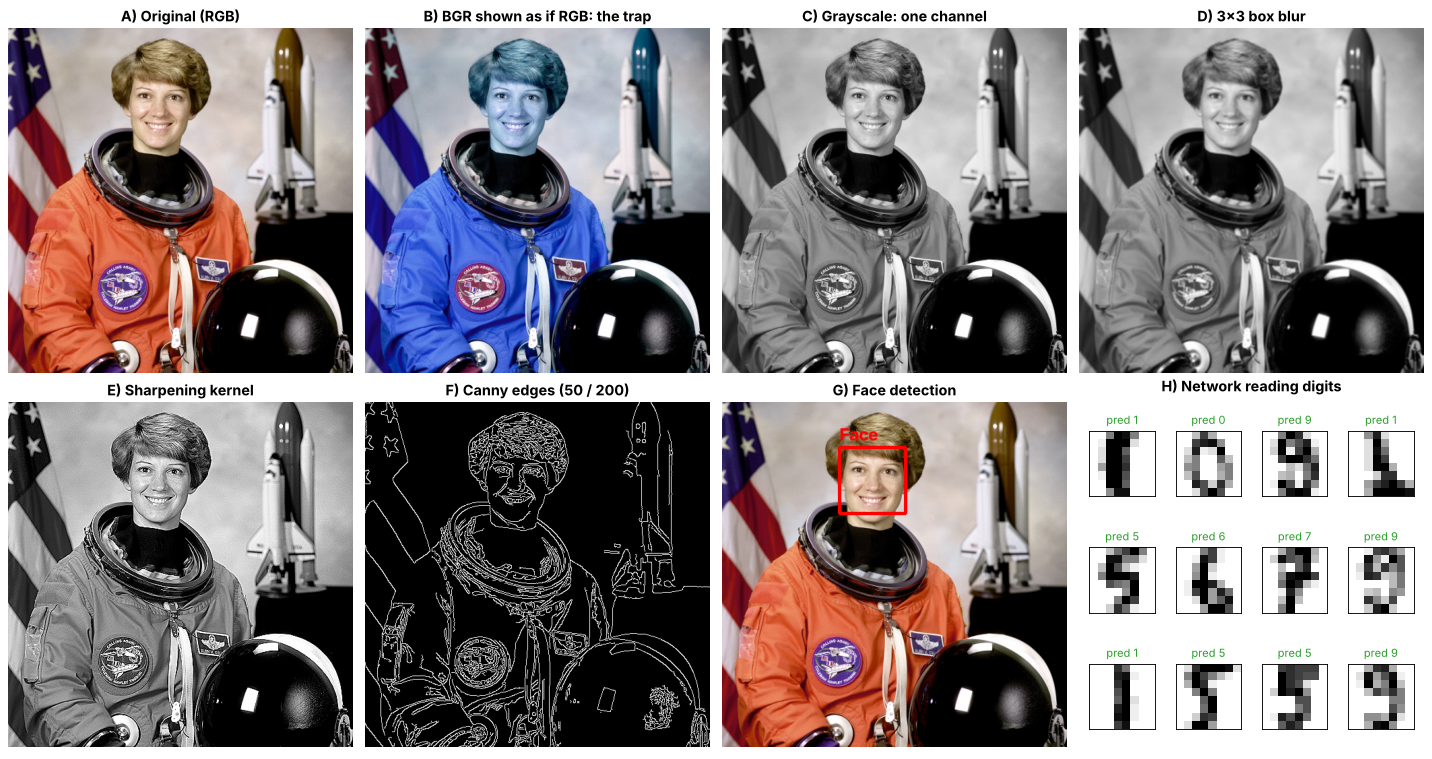

In [13]:
from IPython.display import Image, display
display(Image("computer_vision_master_plot.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)